In [1]:
from google.colab import files
files.upload()
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

Saving kaggle.json to kaggle.json


In [17]:
import kagglehub
import shutil

# Download latest version
path = kagglehub.dataset_download("kaustubhb999/tomatoleaf")
destination = "/content/tomatoleaf"
shutil.copytree(path, destination, dirs_exist_ok=True)

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'tomatoleaf' dataset.
Path to dataset files: /kaggle/input/tomatoleaf


In [20]:
ls "/content/tomatoleaf/tomato/train"


 Tomato___Bacterial_spot/   Tomato___Septoria_leaf_spot/
 Tomato___Early_blight/    'Tomato___Spider_mites Two-spotted_spider_mite'/
 Tomato___healthy/          Tomato___Target_Spot/
 Tomato___Late_blight/      Tomato___Tomato_mosaic_virus/
 Tomato___Leaf_Mold/        Tomato___Tomato_Yellow_Leaf_Curl_Virus/


In [21]:
ls "/content/tomatoleaf/tomato/val"


 Tomato___Bacterial_spot/   Tomato___Septoria_leaf_spot/
 Tomato___Early_blight/    'Tomato___Spider_mites Two-spotted_spider_mite'/
 Tomato___healthy/          Tomato___Target_Spot/
 Tomato___Late_blight/      Tomato___Tomato_mosaic_virus/
 Tomato___Leaf_Mold/        Tomato___Tomato_Yellow_Leaf_Curl_Virus/


In [22]:
import os

DATA_DIR = "/content/tomatoleaf/tomato"


In [23]:
import os
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim

from PIL import Image
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision import transforms
from sklearn.model_selection import train_test_split

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


In [24]:
from torchvision.transforms import v2

mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]

train_transform = v2.Compose([
    v2.ToImage(),
    v2.RandomResizedCrop(224),
    v2.RandomHorizontalFlip(),
    v2.ColorJitter(0.3, 0.3, 0.3),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean, std)
])

val_transform = v2.Compose([
    v2.ToImage(),
    v2.Resize((224, 224)),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean, std)
])

In [ ]:
from torchvision.datasets import ImageFolder

train_dir = "/content/tomatoleaf/tomato/train"
val_dir = "/content/tomatoleaf/tomato/val"

train_dataset = ImageFolder(
    train_dir,
    transform=train_transform
)

val_dataset = ImageFolder(
    val_dir,
    transform=val_transform
)

classes = train_dataset.classes
num_classes = len(classes)

print("Number of classes:", num_classes)
print("Classes:", classes)
print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))

Number of classes: 10
Classes: ['Tomato___Bacterial_spot', 'Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___Leaf_Mold', 'Tomato___Septoria_leaf_spot', 'Tomato___Spider_mites Two-spotted_spider_mite', 'Tomato___Target_Spot', 'Tomato___Tomato_Yellow_Leaf_Curl_Virus', 'Tomato___Tomato_mosaic_virus', 'Tomato___healthy']
Training images: 10000
Validation images: 1000


In [26]:
from torch.utils.data import DataLoader

batch_size = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Training batches: 313
Validation batches: 32


In [27]:
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Number of classes:", num_classes)

Image batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32])
Number of classes: 10


In [30]:
from torchvision import models
import torch.nn as nn

weights = models.ResNet18_Weights.DEFAULT

model = models.resnet18(weights=weights)


In [31]:
# Freeze all pretrained parameters
for param in model.parameters():
    param.requires_grad = False

# Replace the final layer
model.fc = nn.Linear(512, num_classes)
model = model.to(device)
print(model.fc)

trainable_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

total_params = sum(p.numel() for p in model.parameters())

print("Trainable parameters:", trainable_params)
print("Total parameters:", total_params)

Linear(in_features=512, out_features=10, bias=True)
Trainable parameters: 5130
Total parameters: 11181642


In [32]:
images, labels = next(iter(train_loader))
images = images.to(device)
model.eval()

with torch.no_grad():
    outputs = model(images)

print("Input shape:", images.shape)
print("Output shape:", outputs.shape)

Input shape: torch.Size([32, 3, 224, 224])
Output shape: torch.Size([32, 10])


In [35]:
loss_fn = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.fc.parameters(),
    lr=0.001
)

In [36]:
import copy

epochs = 10
best_val_accuracy = 0
best_model_weights = copy.deepcopy(model.state_dict())

for epoch in range(epochs):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = loss_fn(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    train_loss = running_loss / len(train_loader)
    train_accuracy = 100 * correct / total
    model.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)
            outputs = model(images)
            loss = loss_fn(outputs, labels)
            val_loss += loss.item()
            predictions = outputs.argmax(dim=1)
            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    val_loss /= len(val_loader)
    val_accuracy = 100 * val_correct / val_total

    if val_accuracy > best_val_accuracy:
        best_val_accuracy = val_accuracy
        best_model_weights = copy.deepcopy(model.state_dict())

    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"Train Loss: {train_loss:.4f} "
        f"Train Acc: {train_accuracy:.2f}% "
        f"Val Loss: {val_loss:.4f} "
        f"Val Acc: {val_accuracy:.2f}%"
    )

model.load_state_dict(best_model_weights)

print("\nBest validation accuracy:", best_val_accuracy)

Epoch [1/10] Train Loss: 1.2983 Train Acc: 59.93% Val Loss: 0.8198 Val Acc: 73.20%
Epoch [2/10] Train Loss: 0.8067 Train Acc: 75.16% Val Loss: 0.7065 Val Acc: 75.90%
Epoch [3/10] Train Loss: 0.7147 Train Acc: 77.12% Val Loss: 0.5705 Val Acc: 81.80%
Epoch [4/10] Train Loss: 0.6563 Train Acc: 78.88% Val Loss: 0.6462 Val Acc: 79.00%
Epoch [5/10] Train Loss: 0.6272 Train Acc: 79.18% Val Loss: 0.5412 Val Acc: 82.10%
Epoch [6/10] Train Loss: 0.6082 Train Acc: 79.91% Val Loss: 0.5297 Val Acc: 83.00%
Epoch [7/10] Train Loss: 0.5876 Train Acc: 80.36% Val Loss: 0.4981 Val Acc: 83.10%
Epoch [8/10] Train Loss: 0.5816 Train Acc: 80.11% Val Loss: 0.5133 Val Acc: 82.50%
Epoch [9/10] Train Loss: 0.5784 Train Acc: 80.85% Val Loss: 0.5784 Val Acc: 81.10%
Epoch [10/10] Train Loss: 0.5730 Train Acc: 80.75% Val Loss: 0.5371 Val Acc: 82.60%

Best validation accuracy: 83.1


Validation samples: 1000

Classification Report:

                                               precision    recall  f1-score   support

                      Tomato___Bacterial_spot       0.93      0.82      0.87       100
                        Tomato___Early_blight       0.84      0.53      0.65       100
                         Tomato___Late_blight       0.90      0.86      0.88       100
                           Tomato___Leaf_Mold       0.79      0.88      0.83       100
                  Tomato___Septoria_leaf_spot       0.73      0.86      0.79       100
Tomato___Spider_mites Two-spotted_spider_mite       0.77      0.91      0.83       100
                         Tomato___Target_Spot       0.77      0.71      0.74       100
       Tomato___Tomato_Yellow_Leaf_Curl_Virus       0.91      0.94      0.93       100
                 Tomato___Tomato_mosaic_virus       0.78      0.86      0.82       100
                             Tomato___healthy       0.93      0.94      0.94   

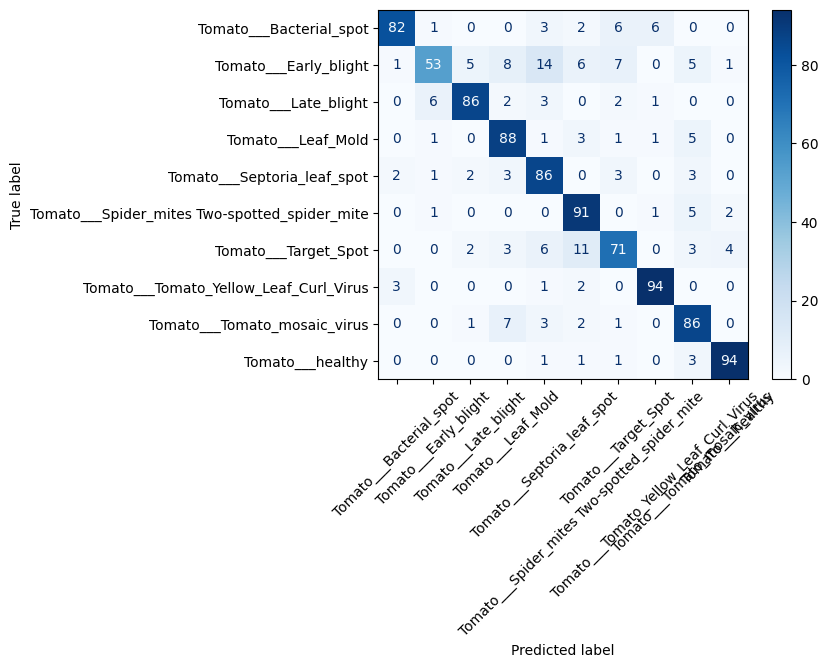

In [41]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import seaborn as sns

model.eval()

y_true = []
y_pred = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)
        outputs = model(images)
        predictions = outputs.argmax(dim=1)
        y_true.extend(labels.numpy())
        y_pred.extend(predictions.cpu().numpy())

print("Validation samples:", len(y_true))
print("\nClassification Report:\n")
print(classification_report(
    y_true,
    y_pred,
    target_names=classes
))

cm = confusion_matrix(y_true, y_pred)
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=classes
).plot(
    cmap="Blues",
    xticks_rotation=45
)
plt.show()